# 04 · Les noms : est-ce que le son d'un nom dit quelque chose du Pokémon ?

L'idée vient de la **symbolique sonore** : en linguistique, on a remarqué que certains sons « vont avec » certaines idées. Par exemple, beaucoup de gens associent les sons durs ou graves (b, d, g) à des choses grosses et lourdes, et les sons doux à des choses petites ou mignonnes. C'est l'idée derrière l'expérience classique « bouba / kiki ».

Des chercheurs ont testé ça sur les Pokémon, c'est ce qu'ils appellent les **Pokémonastics** :
- **Kawahara, Noto & Kumagai (2018)** : en japonais, plus un nom de Pokémon contient de **consonnes voisées** (les kana avec le petit signe ゛, comme ガ, ド, バ), plus le Pokémon est **grand et lourd**. Et plus le nom est **long** (en nombre de mores), plus le Pokémon est **évolué** et **fort**.
- **Shih et al. (2019)** : ils ont testé la même chose dans 6 langues, mais **pas en français**.

Dans ce notebook on fait trois choses :
1. on transforme les noms japonais et français en **variables sonores** (longueur, consonnes voisées, sons durs, sons doux) ;
2. on essaie de **retrouver le résultat de Kawahara** en japonais, puis on regarde si ça marche aussi en français ;
3. on regarde si le son du nom a un lien avec la **popularité** (« un nom court et doux est-il plus aimé ? »).

La méthode, c'est celle du TP1 : on compare des variables avec la **corrélation de Spearman** (elle travaille sur les rangs, donc elle ne suppose pas de relation linéaire et elle n'est pas gênée par les valeurs extrêmes comme le poids).

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import spearmanr

pd.set_option("display.max_columns", 50)
PROC = Path("../data/processed")
table = pd.read_csv(PROC / "table_maitre.csv", index_col="dex")
print(table.shape)

(1025, 31)


## 1. Découverte des noms

In [2]:
table[["nom_en", "nom_fr", "nom_ja", "nom_ja_roma"]].sample(10, random_state=1)

,nom_en,nom_fr,nom_ja,nom_ja_roma
dex,,,,
50,Diglett,Taupiqueur,ディグダ,Digda
526,Gigalith,Gigalithe,ギガイアス,Gigaiath
120,Staryu,Stari,ヒトデマン,Hitodeman
630,Mandibuzz,Vaututrice,バルジーナ,Vulgina
187,Hoppip,Granivol,ハネッコ,Hanecco
692,Clauncher,Flingouste,ウデッポウ,Udeppou
474,Porygon-Z,Porygon-Z,ポリゴンＺ,Porygon-Z
423,Gastrodon,Tritosor,トリトドン,Tritodon
28,Sandslash,Sablaireau,サンドパン,Sandpan


In [3]:
# longueur des noms (en caractères) dans chaque écriture
pd.DataFrame({c: table[c].str.len().describe() for c in ["nom_fr", "nom_ja", "nom_ja_roma"]})

,nom_fr,nom_ja,nom_ja_roma
count,1025.000000,1025.000000,1025.000000
mean,8.241951,4.671220,7.620488
std,1.608691,0.733011,1.721126
min,3.000000,2.000000,2.000000
25%,7.000000,4.000000,6.000000
50%,8.000000,5.000000,7.000000
75%,9.000000,5.000000,9.000000
max,12.000000,6.000000,15.000000


Les noms japonais sont beaucoup plus courts à l'écrit (environ 5 caractères) que les noms français (environ 8 lettres), parce qu'un kana représente une syllabe entière et pas une lettre.

In [4]:
# les caractères des noms français qui ne sont pas des lettres simples
def sans_accents(s):
    return "".join(ch for ch in unicodedata.normalize("NFD", s) if unicodedata.category(ch) != "Mn")

autres_fr = table["nom_fr"].map(lambda s: set(ch for ch in sans_accents(s).lower() if not "a" <= ch <= "z"))
print("caractères spéciaux :", sorted(set().union(*autres_fr)))
table.loc[autres_fr.map(len) > 0, ["nom_fr"]].T

caractères spéciaux : [' ', '-', '.', '0', '2', ':', '♀', '♂']


dex,29,32,122,233,250,439,474,772,805,866,945,984,985,986,987,988,989,990,991,992,993,994,995,1005,1006,1009,1010,1020,1021,1022,1023
nom_fr,Nidoran♀,Nidoran♂,M. Mime,Porygon2,Ho-Oh,Mime Jr.,Porygon-Z,Type:0,Ama-Ama,M. Glaquette,Tag-Tag,Fort-Ivoire,Hurle-Queue,Fongus-Furie,Flotte-Mèche,Rampe-Ailes,Pelage-Sablé,Roue-de-Fer,Hotte-de-Fer,Paume-de-Fer,Têtes-de-Fer,Mite-de-Fer,Épine-de-Fer,Rugit-Lune,Garde-de-Fer,Serpente-Eau,Vert-de-Fer,Feu-Perçant,Ire-Foudre,Roc-de-Fer,Chef-de-Fer


Côté français, quelques noms ont des caractères spéciaux : les ♀/♂ de Nidoran, des points (M. Mime, Mime Jr.), des chiffres (Porygon2, Type:0) et surtout des **tirets**. Les tirets viennent en grande partie des Pokémon Paradoxes de la génération 9 (Fort-Ivoire, Roue-de-Fer…), qui ont des noms composés.

Ces caractères ne se prononcent pas comme des sons du nom (ou alors pas de façon régulière), donc on décide de **ne garder que les lettres** pour coder les sons français.

In [5]:
# les accents dans les noms français
accents = table["nom_fr"].map(lambda s: sorted(set(ch for ch in s.lower() if ch not in "abcdefghijklmnopqrstuvwxyz" and ch.isalpha())))
print("lettres accentuées :", sorted(set(sum(accents, []))))
print("noms avec au moins un accent :", (accents.map(len) > 0).sum())

lettres accentuées : ['â', 'ç', 'è', 'é', 'ê', 'ï', 'ô']
noms avec au moins un accent : 169


169 noms français ont au moins un accent (é, è, ê, â, ï, ô, ç). Pour notre codage, un é reste une voyelle comme un e, et un ç une consonne comme un c : du coup on **enlève les accents** avant de compter, ça évite d'avoir à gérer chaque lettre accentuée à part.

In [6]:
# les noms japonais : est-ce qu'ils sont tous en katakana ?
def est_katakana(ch):
    return "\u30A0" <= ch <= "\u30FF"

autres_ja = table["nom_ja"].map(lambda s: set(ch for ch in s if not est_katakana(ch)))
print("caractères non katakana :", sorted(set().union(*autres_ja)))
table.loc[autres_ja.map(len) > 0, ["nom_fr", "nom_ja", "nom_ja_roma"]]

caractères non katakana : ['♀', '♂', '２', '：', 'Ｚ']


,nom_fr,nom_ja,nom_ja_roma
dex,,,
29,Nidoran♀,ニドラン♀,Nidoran♀
32,Nidoran♂,ニドラン♂,Nidoran♂
233,Porygon2,ポリゴン２,Porygon2
474,Porygon-Z,ポリゴンＺ,Porygon-Z
772,Type:0,タイプ：ヌル,Type:Null


Tous les noms japonais sont en katakana, sauf 5 qui contiennent ♀/♂, un chiffre ou une lettre en pleine largeur (２, Ｚ) ou les deux-points de Type:0. Ce ne sont pas des kana, donc on les **ignore** quand on compte les mores : ça ne touche que 5 noms.

### Ce qu'on a fait et pourquoi

Dans cette partie, on a surtout regardé à quoi ressemblent les noms avant de les coder.

**1. Comparer les trois écritures.** On a regardé la longueur des noms en français, en kana et en romaji. Comme ça, on comprend tout de suite qu'on ne peut pas compter « des lettres » de la même façon dans les deux langues : un kana, c'est une syllabe entière.

**2. Lister les caractères bizarres.** Avant de compter quoi que ce soit, on a cherché tout ce qui n'est pas une lettre ou un kana (♀/♂, tirets, points, chiffres, lettres en pleine largeur). On préfère les voir avant plutôt que de découvrir après coup qu'un symbole a été compté comme un son. Du coup on ne garde que les lettres en français, et on ignore ces caractères en japonais (ils ne touchent que quelques noms).

**3. Enlever les accents.** Pour notre codage, un é reste une voyelle et un ç reste une consonne. Enlever les accents (avec la décomposition Unicode) évite de traiter chaque lettre accentuée à part, sans rien changer à ce qu'on compte.

## 2. Les variables sonores du japonais

On a le choix entre les **kana** (l'écriture japonaise) et le **romaji** (la transcription en lettres latines). On part sur les kana, parce que c'est ce qu'a fait Kawahara (on pourra donc comparer avec son résultat) et parce que les kana collent beaucoup mieux à la prononciation que le romaji, qui n'est pas toujours écrit pareil.

Petit lexique :
- **more** : l'unité de rythme du japonais. En gros, un kana = une more. Les petits ャ ュ ョ ァ ィ ゥ ェ ォ se prononcent avec le kana d'avant (キャ = « kya »), donc on décide de les **coller au kana d'avant** (une seule more pour les deux). Le trait d'allongement ー, le petit ッ (consonne doublée) et ン comptent chacun pour une more, comme en phonologie japonaise.
- **consonne voisée** (ou sonore) : une consonne où les cordes vocales vibrent, comme b, d, g, z. En japonais, elles s'écrivent avec le petit signe **゛ (dakuten)** : カ (ka) → ガ (ga), ト (to) → ド (do), ハ (ha) → バ (ba). Le petit rond ゜ (handakuten, パ = pa) donne un « p », qui n'est pas voisé : on décide donc de **ne compter que les ゛**, comme Kawahara.

Pour compter les dakuten, on décompose chaque kana avec Unicode (forme NFD) : ガ devient カ + ゛, et il suffit de compter les ゛.

In [7]:
PETITS = set("ャュョァィゥェォヮ")
DAKUTEN = "\u3099"

def mores_ja(nom):
    kana = [ch for ch in nom if est_katakana(ch) and ch != "・"]
    return sum(1 for ch in kana if ch not in PETITS)

def voisees_ja(nom):
    return unicodedata.normalize("NFD", nom).count(DAKUTEN)

exemples = table.loc[[25, 6, 95, 143, 384, 133], ["nom_fr", "nom_ja", "nom_ja_roma"]]
exemples["mores"] = exemples["nom_ja"].map(mores_ja)
exemples["voisees"] = exemples["nom_ja"].map(voisees_ja)
exemples

,nom_fr,nom_ja,nom_ja_roma,mores,voisees
dex,,,,,
25,Pikachu,ピカチュウ,Pikachu,4,0
6,Dracaufeu,リザードン,Lizardon,5,2
95,Onix,イワーク,Iwark,4,0
143,Ronflex,カビゴン,Kabigon,4,2
384,Rayquaza,レックウザ,Rayquaza,5,1
133,Évoli,イーブイ,Eievui,4,1


Sur les exemples, ça donne ce qu'on attend : Pikachu ピカチュウ fait 4 mores (pi-ka-chu-u) sans consonne voisée, Dracaufeu リザードン (Rizādon) a 2 voisées (ザ et ド), Ronflex カビゴン (Kabigon) aussi (ビ et ゴ).

In [8]:
noms = pd.DataFrame(index=table.index)
noms["ja_mores"] = table["nom_ja"].map(mores_ja)
noms["ja_voisees"] = table["nom_ja"].map(voisees_ja)
noms["ja_voisees_part"] = noms["ja_voisees"] / noms["ja_mores"]
noms.describe().T

,count,mean,std,min,25%,50%,75%,max
ja_mores,1025.0,4.494634,0.755333,1.0,4.0,5.0,5.00,6.0
ja_voisees,1025.0,0.801951,0.789825,0.0,0.0,1.0,1.00,4.0
ja_voisees_part,1025.0,0.178504,0.178606,0.0,0.0,0.2,0.25,1.0


En moyenne un nom japonais fait 4,5 mores et contient 0,8 consonne voisée. La moitié des noms ont 0 ou 1 consonne voisée.

In [9]:
# les noms les plus courts et les plus longs en mores
d = table[["nom_fr", "nom_ja", "nom_ja_roma"]].assign(mores=noms["ja_mores"])
pd.concat([d.nsmallest(5, "mores"), d.nlargest(5, "mores")])

,nom_fr,nom_ja,nom_ja_roma,mores
dex,,,,
173,Mélo,ピィ,Py,1
151,Mew,ミュウ,Mew,2
240,Magby,ブビィ,Buby,2
921,Pohm,パモ,Pamo,2
971,Toutombe,ボチ,Bochi,2
721,Volcanion,ボルケニオン,Volcanion,6
752,Tarenbulle,オニシズクモ,Onishizukumo,6
765,Gouroutan,ヤレユータン,Yareyuutan,6
766,Quartermac,ナゲツケサル,Nagetukesaru,6


Les noms vont de 1 à 6 mores. Le seul nom à 1 more, Mélo ピィ, est un cas limite de notre règle : le petit ィ est collé au ピ, alors qu'ici il se prononce « pii » (2 mores). Même chose pour Magby ブビィ. On garde quand même la règle telle quelle : elle est juste pour la grande majorité des noms, et ça ne concerne que quelques Pokémon.

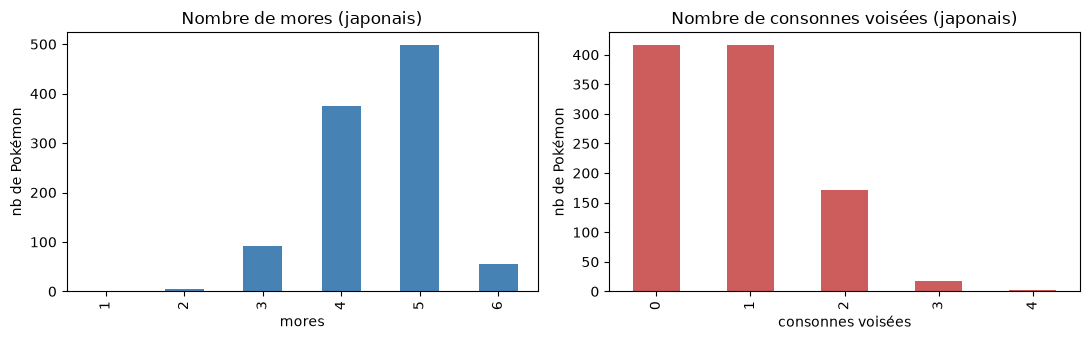

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
noms["ja_mores"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Nombre de mores (japonais)", xlabel="mores", ylabel="nb de Pokémon")
noms["ja_voisees"].value_counts().sort_index().plot.bar(ax=axes[1], color="indianred")
axes[1].set(title="Nombre de consonnes voisées (japonais)", xlabel="consonnes voisées", ylabel="nb de Pokémon")
plt.tight_layout()

### Ce qu'on a fait et pourquoi

**1. Partir des kana plutôt que du romaji.** On a codé les noms japonais à partir des kana parce que c'est ce qu'a fait Kawahara (on peut donc comparer avec son résultat) et parce que les kana suivent la prononciation, alors que le romaji n'est pas toujours écrit pareil.

**2. Compter des mores.** La more, c'est l'unité de rythme du japonais, donc c'est la bonne mesure de la longueur d'un nom japonais (bien mieux que le nombre de caractères). On a collé les petits kana (ャ, ュ, ョ…) au kana d'avant parce qu'ils se prononcent avec lui. On sait que la règle se trompe sur quelques cas (Mélo, Magby), mais elle est juste pour presque tous les noms, donc on l'a gardée simple.

**3. Compter les consonnes voisées avec le ゛.** En décomposant chaque kana avec Unicode, ガ devient カ + ゛, et il suffit de compter les ゛. C'est simple, sans liste à la main, et c'est exactement la définition de Kawahara (on ne compte pas le ゜, qui donne un « p », non voisé).

**4. Les diagrammes en barres.** Mores et consonnes voisées sont des petits nombres entiers (de 0 à 6), donc un diagramme en barres montre directement combien de Pokémon il y a pour chaque valeur. Un histogramme avec des classes n'aurait rien apporté de plus.

## 3. Les variables sonores du français

Ici c'est plus compliqué : **l'orthographe française n'est pas la prononciation**. Par exemple le « s » de « Salamèche » se prononce s, mais celui de « Rosélia » se prononce z ; le « c » de « Carapuce » est dur (k) alors que le deuxième est doux (s) ; beaucoup de lettres finales sont muettes.

L'idéal serait une transcription phonétique des noms, mais il n'en existe pas pour les noms français de Pokémon, et la faire à la main pour 1 025 noms serait trop long. Du coup on décide de **coder à partir des lettres**, en restant simple :

- **nb de lettres** (sans espaces ni ponctuation) ;
- **nb de syllabes (approché)** : on compte les groupes de voyelles qui se suivent (« ou », « ai » comptent pour un), et on enlève un « e » final muet ;
- **consonnes voisées** : b, d, g, v, z, j ;
- **occlusives « dures »** : les consonnes qui « claquent », p, t, k, b, d, g, plus q et le c dur (c devant a, o, u ou une consonne) ;
- **sonantes « douces »** : m, n, l, r.

On sait que certains sons seront mal comptés (s entre deux voyelles, g devant e/i qui se prononce j, lettres muettes…), on le gardera en tête au moment de lire les résultats.

In [11]:
VOYELLES = "aeiouy"

def prepare_fr(nom):
    return re.sub(r"[^a-z]", "", sans_accents(nom).lower())

def syllabes_fr(nom):
    s = prepare_fr(nom)
    groupes = re.findall(f"[{VOYELLES}]+", s)
    n = len(groupes)
    if n > 1 and s.endswith("e") and not s.endswith(("ee", "ie")) and len(s) > 1 and s[-2] not in VOYELLES:
        n -= 1  # e muet final : Salameche -> sa-la-meche
    return max(n, 1)

def voisees_fr(nom):
    return sum(prepare_fr(nom).count(c) for c in "bdgvzj")

def occlusives_fr(nom):
    s = prepare_fr(nom)
    n = sum(s.count(c) for c in "ptkbdgq")
    n += len(re.findall(r"c(?=[aou]|[^aeiouyh]|$)", s))  # c dur
    return n

def sonantes_fr(nom):
    return sum(prepare_fr(nom).count(c) for c in "mnlr")

exemples = table.loc[[1, 4, 7, 25, 143, 315, 122], ["nom_fr"]].copy()
for f in [syllabes_fr, voisees_fr, occlusives_fr, sonantes_fr]:
    exemples[f.__name__] = exemples["nom_fr"].map(f)
exemples

,nom_fr,syllabes_fr,voisees_fr,occlusives_fr,sonantes_fr
dex,,,,,
1,Bulbizarre,3,3,2,3
4,Salamèche,3,0,0,2
7,Carapuce,3,0,2,1
25,Pikachu,3,0,2,0
143,Ronflex,2,0,0,3
315,Rosélia,3,0,0,2
122,M. Mime,1,0,0,3


Sur les exemples, le codage marche à peu près. Mais on voit déjà ses limites : le x de Ronflex (qui se prononce « ks ») n'est compté ni comme occlusive ni comme voisée, et le s de Rosélia (qui se prononce z) n'est pas compté comme voisé. M. Mime ne fait qu'une syllabe parce que le e final est retiré.

Ces erreurs restent rares, donc on garde le codage comme ça. Un nom long a forcément plus de consonnes voisées qu'un nom court : pour ne pas juste mesurer la longueur une deuxième fois, on calcule aussi chaque variable **en proportion** (du nombre de lettres en français, du nombre de mores en japonais).

In [12]:
noms["fr_lettres"] = table["nom_fr"].map(lambda s: len(prepare_fr(s)))
noms["fr_syllabes"] = table["nom_fr"].map(syllabes_fr)
noms["fr_voisees"] = table["nom_fr"].map(voisees_fr)
noms["fr_occlusives"] = table["nom_fr"].map(occlusives_fr)
noms["fr_sonantes"] = table["nom_fr"].map(sonantes_fr)
# en proportion des lettres, pour ne pas juste mesurer la longueur du nom
for c in ["fr_voisees", "fr_occlusives", "fr_sonantes"]:
    noms[c + "_part"] = noms[c] / noms["fr_lettres"]
noms.filter(like="fr_").describe().T

,count,mean,std,min,25%,50%,75%,max
fr_lettres,1025.0,8.198049,1.577056,3.0,7.000000,8.000000,9.000000,12.000000
fr_syllabes,1025.0,2.831220,0.658331,1.0,2.000000,3.000000,3.000000,5.000000
fr_voisees,1025.0,0.783415,0.819631,0.0,0.000000,1.000000,1.000000,4.000000
fr_occlusives,1025.0,1.670244,1.011913,0.0,1.000000,2.000000,2.000000,4.000000
fr_sonantes,1025.0,1.969756,1.032699,0.0,1.000000,2.000000,3.000000,6.000000
fr_voisees_part,1025.0,0.096773,0.103161,0.0,0.000000,0.100000,0.142857,0.571429
fr_occlusives_part,1025.0,0.204797,0.122814,0.0,0.125000,0.200000,0.285714,0.666667
fr_sonantes_part,1025.0,0.237998,0.115981,0.0,0.166667,0.222222,0.300000,0.666667


Un nom français fait en moyenne 8,2 lettres et 2,8 syllabes, avec 0,8 consonne voisée, 1,7 occlusive et 2 sonantes.

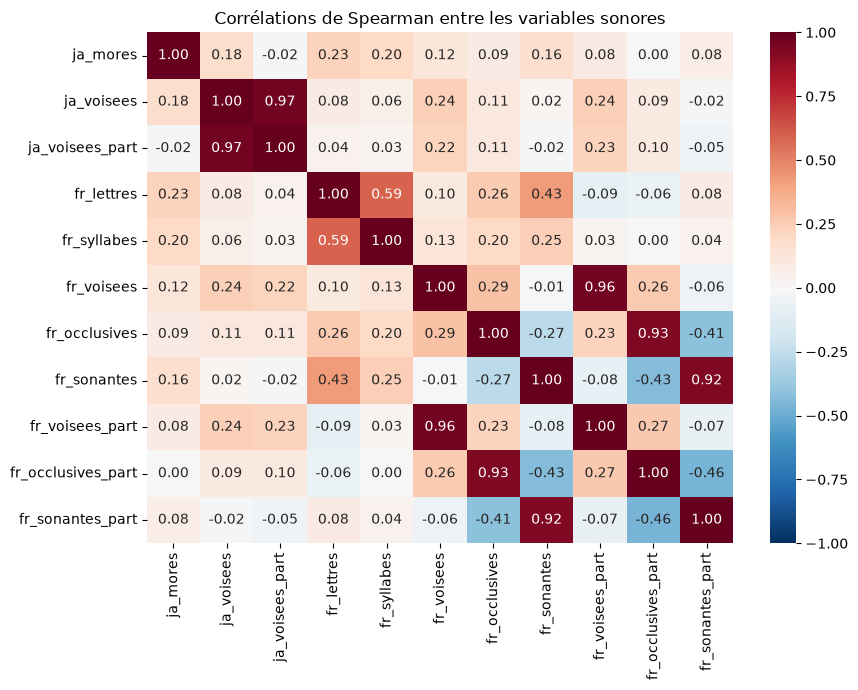

In [13]:
# les variables sont-elles liées entre elles ? (Spearman)
plt.figure(figsize=(9, 7))
sns.heatmap(noms.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Corrélations de Spearman entre les variables sonores")
plt.tight_layout()

Les variables « en nombre » et « en proportion » sont très liées entre elles (0,92 à 0,97), c'est normal. Plus intéressant : le nombre de mores en japonais et la longueur en français ne sont que faiblement liés (0,20 à 0,23), et les consonnes voisées JP et FR aussi (0,24). Le nom français n'est donc pas une simple traduction du nom japonais : c'est souvent un nom inventé à part, d'où l'intérêt de tester les deux langues.

### Ce qu'on a fait et pourquoi

**1. Coder à partir de l'orthographe.** L'idéal aurait été une transcription phonétique des noms français, mais il n'en existe pas pour les Pokémon et la faire à la main pour 1 025 noms était trop long. Du coup on a codé à partir des lettres, avec des règles simples (groupes de voyelles pour les syllabes, e muet final, c dur). On sait que ça se trompe sur certains sons (le s de Rosélia, le x de Ronflex), et on l'a vérifié sur des exemples connus pour voir à quel point.

**2. Des familles de sons plutôt que chaque lettre.** On a regroupé les consonnes en trois familles qui ont un sens en symbolique sonore : voisées (b, d, g, v, z, j), occlusives « dures » (p, t, k…) et sonantes « douces » (m, n, l, r). Ça donne quelques variables qu'on peut interpréter, au lieu d'une variable par lettre.

**3. Des variables en proportion.** Un nom long a forcément plus de consonnes de chaque sorte. Si on ne regardait que les nombres, on mesurerait juste la longueur une deuxième fois. Du coup on a aussi calculé chaque variable en proportion du nombre de lettres (ou de mores en japonais).

**4. La heatmap des corrélations de Spearman.** Avant d'utiliser les variables, on a voulu voir lesquelles disent la même chose. La heatmap montre toutes les paires d'un coup, avec une échelle de couleurs centrée sur 0 (rouge = lié dans le même sens, bleu = sens inverse). On a pris Spearman parce que ce sont des petits comptages pas du tout « normaux », et qu'on veut juste savoir si deux variables montent ensemble.

## 4. Retrouver le résultat de Kawahara (japonais)

On calcule la corrélation de Spearman entre les variables sonores et la taille, le poids, le total des stats et le stade d'évolution.

Pour le **stade**, on enlève les Pokémon « sans évolution » (la catégorie à part du notebook 01) : pour eux le stade ne veut rien dire, et ce sont souvent des légendaires très forts qui brouilleraient le lien. On les garde par contre pour la taille, le poids et les stats, qui ont du sens pour tout le monde.

La **p-valeur** dit si la corrélation pourrait être due au hasard : en dessous de 0,05 on considère en général que le lien est significatif. Avec 1 025 Pokémon, même une petite corrélation (0,1) devient significative, donc il faut regarder la **force** du rho et pas seulement la p-valeur.

In [14]:
def spearman_table(variables, cibles, data):
    lignes = []
    for v in variables:
        for c in cibles:
            d = data[[v, c]].dropna()
            rho, p = spearmanr(d[v], d[c])
            lignes.append({"variable": v, "cible": c, "rho": round(rho, 3), "p_valeur": p, "n": len(d)})
    return pd.DataFrame(lignes)

data = noms.join(table[["taille_m", "poids_kg", "total_stats", "stade", "stade_categorie", "generation"]])
data["stade_si_evolution"] = data["stade"].where(data["stade_categorie"] != "sans évolution")

cibles_physiques = ["taille_m", "poids_kg", "total_stats", "stade_si_evolution"]
res_ja = spearman_table(["ja_mores", "ja_voisees", "ja_voisees_part"], cibles_physiques, data)
res_ja.pivot(index="variable", columns="cible", values="rho")

cible,poids_kg,stade_si_evolution,taille_m,total_stats
variable,,,,
ja_mores,0.365,0.443,0.403,0.424
ja_voisees,0.265,0.205,0.241,0.194
ja_voisees_part,0.195,0.115,0.161,0.105


In [15]:
res_ja

,variable,cible,rho,p_valeur,n
0,ja_mores,taille_m,0.403,3.183516e-41,1025
1,ja_mores,poids_kg,0.365,1.314539e-33,1025
2,ja_mores,total_stats,0.424,6.816476e-46,1025
3,ja_mores,stade_si_evolution,0.443,5.907153e-41,824
4,ja_voisees,taille_m,0.241,4.825773e-15,1025
5,ja_voisees,poids_kg,0.265,7.151104e-18,1025
6,ja_voisees,total_stats,0.194,3.873118e-10,1025
7,ja_voisees,stade_si_evolution,0.205,3.084298e-09,824
8,ja_voisees_part,taille_m,0.161,2.212427e-07,1025
9,ja_voisees_part,poids_kg,0.195,3.059418e-10,1025


On retrouve bien le résultat de Kawahara en japonais :
- plus le nom a de **mores**, plus le Pokémon est grand (rho = 0,40), lourd (0,37), fort (0,42) et évolué (0,44) ;
- plus il a de **consonnes voisées**, plus il est lourd (0,27) et grand (0,24), et un peu plus fort (0,19) et évolué (0,21).

Toutes les p-valeurs sont très petites (en dessous de 0,001). Le lien le plus fort, c'est la **longueur** du nom. En proportion de la longueur, l'effet des consonnes voisées reste là mais il est plus faible (0,16 à 0,20 pour la taille et le poids).

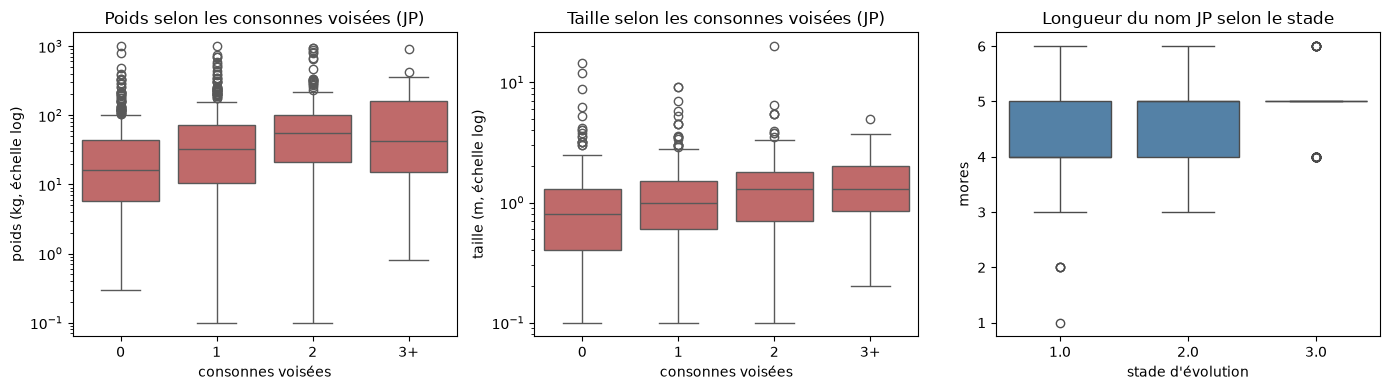

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
data["voisees_cl"] = data["ja_voisees"].clip(upper=3).map(lambda x: "3+" if x == 3 else str(x))
ordre = ["0", "1", "2", "3+"]
sns.boxplot(data=data, x="voisees_cl", y="poids_kg", order=ordre, ax=axes[0], color="indianred")
axes[0].set(yscale="log", title="Poids selon les consonnes voisées (JP)", xlabel="consonnes voisées", ylabel="poids (kg, échelle log)")
sns.boxplot(data=data, x="voisees_cl", y="taille_m", order=ordre, ax=axes[1], color="indianred")
axes[1].set(yscale="log", title="Taille selon les consonnes voisées (JP)", xlabel="consonnes voisées", ylabel="taille (m, échelle log)")
sns.boxplot(data=data.dropna(subset=["stade_si_evolution"]), x="stade_si_evolution", y="ja_mores", ax=axes[2], color="steelblue")
axes[2].set(title="Longueur du nom JP selon le stade", xlabel="stade d'évolution", ylabel="mores")
plt.tight_layout()

Sur les boxplots, le poids médian passe de 16 kg (aucune consonne voisée) à 32,5 kg (une) puis 55 kg (deux), et la taille médiane de 0,8 m à 1,3 m. Pour 3 voisées ou plus le poids redescend un peu (42 kg), mais il y a très peu de noms dans ce groupe. Et les noms s'allongent bien d'un stade à l'autre.

### Ce qu'on a fait et pourquoi

**1. La corrélation de Spearman (TP1).** Pour retrouver Kawahara, on compare les variables sonores à la taille, au poids, aux stats et au stade. On a pris Spearman parce que le poids et la taille ont des valeurs extrêmes énormes (des Pokémon de quelques grammes et d'autres de plusieurs centaines de kilos) : Pearson serait tiré par ces quelques Pokémon. Spearman travaille sur les rangs, donc il est insensible à ça, et il ne suppose pas que le lien est une droite.

**2. Regarder le rho, pas seulement la p-valeur.** Avec 1 025 Pokémon, même un lien minuscule devient « significatif ». Du coup on lit d'abord la force du lien (le rho), et la p-valeur sert juste à vérifier que ce n'est pas du hasard.

**3. Enlever les « sans évolution » pour le stade.** Pour eux, le stade ne veut rien dire, et ce sont souvent des légendaires très forts qui auraient brouillé le lien entre la longueur du nom et l'évolution. On les a gardés pour la taille, le poids et les stats, qui ont du sens pour tout le monde.

**4. Les boxplots avec une échelle log.** Pour montrer le lien entre consonnes voisées et poids, on a fait un boxplot par nombre de voisées : on voit la médiane et l'étalement de chaque groupe, ce qui est plus lisible qu'un nuage de 1 025 points sur des valeurs entières. L'axe du poids et de la taille est en échelle log, sinon les quelques Pokémon énormes écraseraient toutes les boîtes en bas du graphique. On a regroupé « 3 et plus » parce que ces groupes sont tout petits.

## 5. Et en français ?

In [17]:
vars_fr = ["fr_lettres", "fr_syllabes", "fr_voisees", "fr_voisees_part", "fr_occlusives_part", "fr_sonantes_part"]
res_fr = spearman_table(vars_fr, cibles_physiques, data)
res_fr.pivot(index="variable", columns="cible", values="rho")

cible,poids_kg,stade_si_evolution,taille_m,total_stats
variable,,,,
fr_lettres,0.027,0.126,0.059,0.063
fr_occlusives_part,-0.025,-0.049,-0.040,-0.058
fr_sonantes_part,0.060,0.113,0.057,0.033
fr_syllabes,0.053,0.118,0.076,0.099
fr_voisees,0.096,0.068,0.089,0.070
fr_voisees_part,0.089,0.051,0.085,0.056


In [18]:
res_fr

,variable,cible,rho,p_valeur,n
0,fr_lettres,taille_m,0.059,0.057027,1025
1,fr_lettres,poids_kg,0.027,0.387738,1025
2,fr_lettres,total_stats,0.063,0.044437,1025
3,fr_lettres,stade_si_evolution,0.126,0.000299,824
4,fr_syllabes,taille_m,0.076,0.015534,1025
5,fr_syllabes,poids_kg,0.053,0.092840,1025
6,fr_syllabes,total_stats,0.099,0.001491,1025
7,fr_syllabes,stade_si_evolution,0.118,0.000713,824
8,fr_voisees,taille_m,0.089,0.004374,1025
9,fr_voisees,poids_kg,0.096,0.002000,1025


En français, c'est beaucoup plus faible. Les liens vont dans le même sens que le japonais pour les consonnes voisées (0,09 à 0,10 avec la taille et le poids) et la longueur (0,12 avec le stade), mais les rho ne dépassent jamais 0,13. Avec 1 025 Pokémon certains sont « significatifs » (p < 0,05), mais un rho de 0,1 veut dire un lien presque invisible. Les occlusives « dures » ne sont liées à rien (p > 0,05 partout).

On ne peut pas trancher entre deux explications : soit les noms français n'ont vraiment pas été pensés avec cette symbolique, soit notre codage à partir de l'orthographe est trop approximatif et affaiblit les liens. On le dira comme ça dans les conclusions.

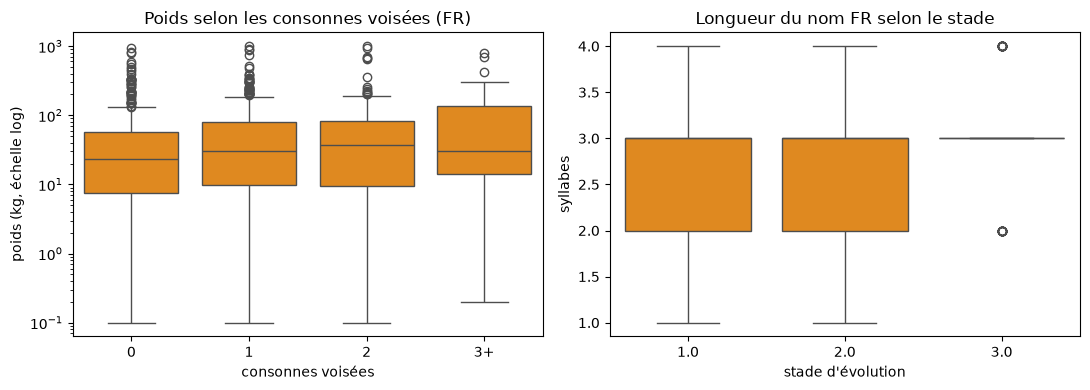

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
data["fr_voisees_cl"] = data["fr_voisees"].clip(upper=3).map(lambda x: "3+" if x == 3 else str(x))
sns.boxplot(data=data, x="fr_voisees_cl", y="poids_kg", order=ordre, ax=axes[0], color="darkorange")
axes[0].set(yscale="log", title="Poids selon les consonnes voisées (FR)", xlabel="consonnes voisées", ylabel="poids (kg, échelle log)")
sns.boxplot(data=data.dropna(subset=["stade_si_evolution"]), x="stade_si_evolution", y="fr_syllabes", ax=axes[1], color="darkorange")
axes[1].set(title="Longueur du nom FR selon le stade", xlabel="stade d'évolution", ylabel="syllabes")
plt.tight_layout()

### Ce qu'on a fait et pourquoi

**1. La même méthode qu'en japonais.** On a gardé exactement les mêmes cibles, le même Spearman et la même présentation que pour le japonais. Comme ça, si le français donne des liens plus faibles, on sait que ça ne vient pas d'une méthode différente.

**2. Comparer les tailles d'effet.** Plusieurs liens passent sous p = 0,05, mais avec des rho autour de 0,1. Du coup on a comparé les rho français aux rho japonais plutôt que de compter les liens « significatifs ».

**3. Ne pas trancher trop vite.** Des liens faibles en français peuvent venir des noms eux-mêmes ou de notre codage approximatif à partir de l'orthographe. On ne peut pas séparer les deux avec ces données, donc on garde les deux explications.

**4. Les boxplots.** On a fait les mêmes boxplots qu'en japonais (poids selon les voisées en échelle log, longueur selon le stade) pour pouvoir comparer les deux langues à l'œil.

## 6. Le son du nom et la popularité

On ne fusionne pas les sources de popularité : un Pokémon peut être bien classé chez un public et moins chez un autre, et les sources n'ont pas le même nombre de votants. On regarde donc chaque source séparément, en **percentile** (« ce Pokémon fait mieux que X % des autres ») :
- **Reddit 2019** : percentile des votes sur les 809 Pokémon des générations 1 à 7 ;
- **Johto Times 2025** : le pourcentage n'a de sens qu'à l'intérieur d'une génération (chaque participant vote dans chaque génération), donc on prend le percentile **dans sa génération**.

In [20]:
pop = pd.DataFrame(index=table.index)
pop["reddit_pct"] = table["reddit_votes"].rank(pct=True)
pop["johto_pct"] = table.groupby("generation")["johto_pct_generation"].rank(pct=True)
pop.describe().T

,count,mean,std,min,25%,50%,75%,max
reddit_pct,809.0,0.500618,0.288797,0.00309,0.254017,0.493820,0.749691,1.0
johto_pct,1025.0,0.504390,0.288768,0.00641,0.250000,0.503311,0.753205,1.0


Les deux percentiles vont bien de 0 à 1 avec une médiane autour de 0,5. Reddit n'a que 809 Pokémon (générations 1 à 7).

In [21]:
data = data.join(pop)
vars_pop = ["ja_mores", "ja_voisees", "ja_voisees_part"] + vars_fr
res_pop = spearman_table(vars_pop, ["reddit_pct", "johto_pct"], data)
res_pop.pivot(index="variable", columns="cible", values="rho")

cible,johto_pct,reddit_pct
variable,,
fr_lettres,-0.024,-0.071
fr_occlusives_part,-0.082,-0.002
fr_sonantes_part,0.023,0.002
fr_syllabes,0.015,-0.004
fr_voisees,-0.032,-0.028
fr_voisees_part,-0.028,-0.013
ja_mores,0.046,-0.027
ja_voisees,0.030,0.038
ja_voisees_part,0.006,0.035


In [22]:
res_pop

,variable,cible,rho,p_valeur,n
0,ja_mores,reddit_pct,-0.027,0.449283,809
1,ja_mores,johto_pct,0.046,0.138774,1025
2,ja_voisees,reddit_pct,0.038,0.282151,809
3,ja_voisees,johto_pct,0.030,0.340287,1025
4,ja_voisees_part,reddit_pct,0.035,0.315290,809
5,ja_voisees_part,johto_pct,0.006,0.844630,1025
6,fr_lettres,reddit_pct,-0.071,0.043885,809
7,fr_lettres,johto_pct,-0.024,0.441413,1025
8,fr_syllabes,reddit_pct,-0.004,0.914255,809
9,fr_syllabes,johto_pct,0.015,0.626233,1025


Toutes sources et tous stades confondus, le son du nom n'a **presque aucun lien** avec la popularité : tous les rho sont entre -0,08 et 0,05. Seuls deux liens passent sous p = 0,05 (lettres FR ↔ Reddit, -0,07 ; part d'occlusives FR ↔ Johto, -0,08), mais ils sont minuscules et ne se retrouvent pas dans l'autre source.

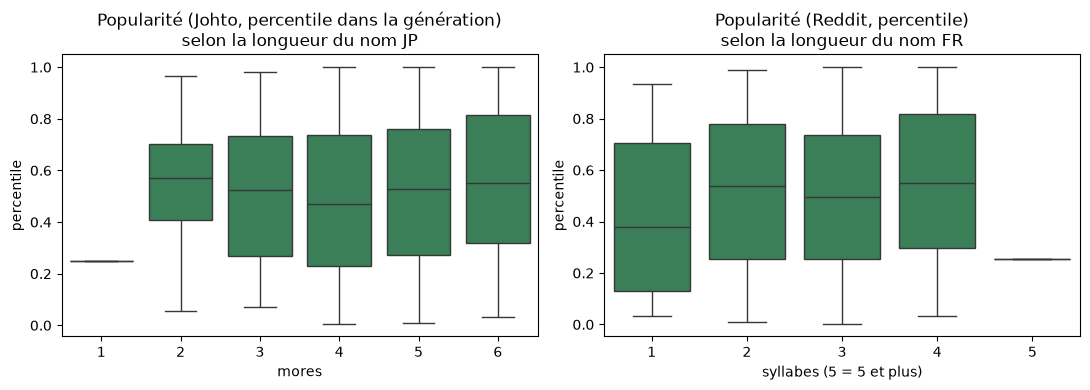

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=data, x="ja_mores", y="johto_pct", ax=axes[0], color="seagreen")
axes[0].set(title="Popularité (Johto, percentile dans la génération)\nselon la longueur du nom JP", xlabel="mores", ylabel="percentile")
sns.boxplot(data=data, x=data["fr_syllabes"].clip(upper=5), y="reddit_pct", ax=axes[1], color="seagreen")
axes[1].set(title="Popularité (Reddit, percentile)\nselon la longueur du nom FR", xlabel="syllabes (5 = 5 et plus)", ylabel="percentile")
plt.tight_layout()

Sur les boxplots, la popularité médiane tourne autour de 0,5 quelle que soit la longueur du nom. Les seules exceptions sont les groupes extrêmes (1 more, 5 syllabes ou plus), mais il n'y a que quelques noms dedans, donc ça ne veut pas dire grand-chose.

Attention : un lien entre le nom et la popularité peut passer par autre chose. Par exemple, si les noms longs sont ceux des Pokémon évolués et forts, et que les Pokémon évolués sont plus aimés, alors on verra un lien « nom long ↔ populaire » qui vient en fait du stade. On regarde donc la même corrélation **à stade égal**.

In [24]:
par_stade = []
for stade, d in data.groupby("stade_categorie"):
    for v in ["ja_mores", "ja_voisees", "fr_syllabes", "fr_voisees"]:
        for c in ["reddit_pct", "johto_pct"]:
            dd = d[[v, c]].dropna()
            rho, p = spearmanr(dd[v], dd[c])
            par_stade.append({"stade": stade, "variable": v, "cible": c, "rho": round(rho, 3), "p_valeur": round(p, 4), "n": len(dd)})
par_stade = pd.DataFrame(par_stade)
par_stade.pivot_table(index=["variable", "cible"], columns="stade", values="rho")

stade                   sans évolution  stade 1  stade 2  stade 3
variable    cible                                                
fr_syllabes johto_pct           -0.203   -0.010    0.003    0.148
            reddit_pct          -0.220   -0.004   -0.025    0.011
fr_voisees  johto_pct           -0.076   -0.131   -0.019    0.093
            reddit_pct          -0.102   -0.141   -0.012    0.161
ja_mores    johto_pct           -0.316   -0.214    0.061    0.143
            reddit_pct          -0.339   -0.107   -0.087   -0.134
ja_voisees  johto_pct           -0.020   -0.075   -0.054    0.038
            reddit_pct          -0.087    0.023   -0.043   -0.025

In [25]:
# les p-valeurs et les effectifs correspondants
par_stade.pivot_table(index=["variable", "cible"], columns="stade", values=["p_valeur", "n"])

n                               p_valeur  \
stade                  sans évolution stade 1 stade 2 stade 3 sans évolution   
variable    cible                                                              
fr_syllabes johto_pct           201.0   340.0   363.0   121.0         0.0039   
            reddit_pct          139.0   282.0   290.0    98.0         0.0094   
fr_voisees  johto_pct           201.0   340.0   363.0   121.0         0.2860   
            reddit_pct          139.0   282.0   290.0    98.0         0.2331   
ja_mores    johto_pct           201.0   340.0   363.0   121.0         0.0000   
            reddit_pct          139.0   282.0   290.0    98.0         0.0000   
ja_voisees  johto_pct           201.0   340.0   363.0   121.0         0.7746   
            reddit_pct          139.0   282.0   290.0    98.0         0.3088   

                                                
stade                  stade 1 stade 2 stade 3  
variable    cible                               
fr_syllabes johto_pct   0.8551  0.9609  0.1060  
            reddit_pct  0.9455  0.6659  0.9149  
fr_voisees  johto_pct   0.0160  0.7182  0.3091  
            reddit_pct  0.0175  0.8396  0.1128  
ja_mores    johto_pct   0.0001  0.2491  0.1164  
            reddit_pct  0.0729  0.1385  0.1896  
ja_voisees  johto_pct   0.1704  0.3078  0.6785  
            reddit_pct  0.7060  0.4693  0.8047

À stade égal, ça change un peu :
- chez les Pokémon **sans évolution**, les noms longs sont nettement **moins populaires**, dans les deux sources et dans les deux langues : rho = -0,32 (Johto) et -0,34 (Reddit) pour les mores JP, -0,20 et -0,22 pour les syllabes FR, avec des p-valeurs sous 0,01 ;
- chez les **stades 1**, les noms JP longs sont un peu moins aimés au Johto Times (-0,21, p = 0,0001), mais pas significativement sur Reddit (-0,11, p = 0,07) ; et plus il y a de consonnes voisées FR, moins le Pokémon est aimé (-0,13 et -0,14, p < 0,02) ;
- aux stades 2 et 3, rien de significatif.

Le lien global quasi nul cachait donc des liens négatifs dans certains groupes seulement. On reste prudent sur le groupe « sans évolution » : il mélange des légendaires (aux noms souvent longs) et des Pokémon ordinaires, donc le lien peut venir de cette différence plutôt que du nom lui-même.

### Ce qu'on a fait et pourquoi

**1. Chaque source séparément, en percentile.** On n'a pas fusionné Reddit et le Johto Times en un seul score : les deux publics ne sont pas les mêmes et n'ont pas le même nombre de votants. On a pris le percentile pour avoir la même échelle (0 à 1) dans les deux sources. Pour le Johto Times, c'est le percentile dans la génération, parce que les votes se font génération par génération.

**2. Spearman entre le son et la popularité.** Même raison que plus haut : on veut savoir si « plus de X » va avec « plus populaire », sans supposer de droite. Et un percentile, c'est déjà un rang.

**3. Les boxplots popularité × longueur.** Ils montrent si la popularité médiane bouge selon la longueur du nom. On a regroupé les noms de 5 syllabes et plus parce qu'il y en a très peu, et on n'interprète pas les groupes extrêmes, qui ne contiennent que quelques noms.

**4. Refaire la corrélation à stade égal.** Un lien entre le nom et la popularité peut passer par une troisième variable. Par exemple, les noms longs sont ceux des Pokémon évolués, et les évolués sont plus aimés. Pour ne pas se faire avoir, on a recalculé Spearman **dans chaque catégorie de stade**. C'est plus simple à lire qu'une régression avec plein de variables, et ça a montré des liens qui disparaissaient dans le calcul global. On reste quand même prudent sur le groupe « sans évolution », qui mélange légendaires et Pokémon ordinaires : le lien peut venir de ce mélange plutôt que du nom.

## 7. Export

In [26]:
noms.to_csv(PROC / "noms_variables.csv")
print("écrit :", PROC / "noms_variables.csv", noms.shape)

écrit : ../data/processed/noms_variables.csv (1025, 11)
